# Phoenix Autocall on a Worst-of Basket: Monte Carlo Pricing and Structuring

**Goal.** Price the structured product most sold to French retail and private banking
clients, explain where its coupon comes from, and show how a structurer sets the terms.

**The product (term sheet).**

| Feature | Term |
|---|---|
| Underlyings | Worst-of two stocks (performance of the worse one counts) |
| Maturity | 3 years, quarterly observations |
| Coupon | 2.5% per quarter (10% p.a.) if the worst-of is at or above **70%** |
| Memory | Missed coupons are paid later if the barrier is met again |
| Autocall | From year 1, early redemption at 100% if the worst-of is at or above **100%** |
| Capital | At maturity, 100% back if the worst-of is at or above **60%**, otherwise the worst-of performance |

**Plan.** 1. Simulate correlated paths · 2. Price and check convergence · 3. Understand
the note's life (calls, coupons, losses) · 4. Sensitivities · 5. Structuring: fair coupon vs
volatility and correlation.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("autocall.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/02-autocall-pricer")

from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from autocall import Phoenix, Market, simulate_performances, price, fair_coupon, sensitivities

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"

note, mkt = Phoenix(), Market()
print(note); print(mkt)

Phoenix(maturity=3.0, obs_per_year=4, autocall_barrier=1.0, coupon_barrier=0.7, protection_barrier=0.6, coupon=0.025, memory=True, first_call_obs=4, notional=100.0)
Market(vols=(0.25, 0.3), divs=(0.02, 0.01), corr=0.6, r=0.03)


## 1. Simulating the underlyings

Each stock follows a risk-neutral geometric Brownian motion,
$S_k(t+\Delta t) = S_k(t)\exp\big((r - q_k - \tfrac12\sigma_k^2)\Delta t + \sigma_k\sqrt{\Delta t}\,Z_k\big)$,
with correlated shocks $Z = L\,\varepsilon$ where $LL^\top$ is the correlation matrix
(Cholesky decomposition). Because the barriers are only observed quarterly, the paths are
simulated **exactly** from one observation date to the next.

**Antithetic variates:** each draw $\varepsilon$ is paired with $-\varepsilon$, which cancels
part of the sampling noise for free.

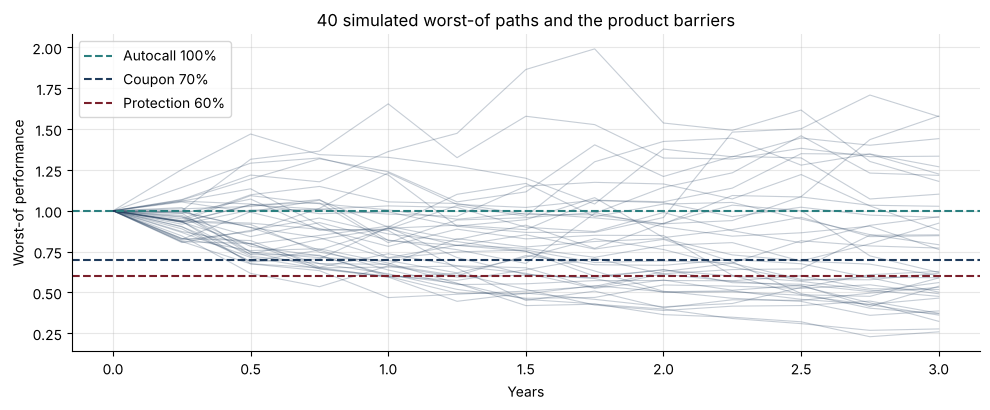

In [2]:
perf = simulate_performances(note, mkt, n_paths=2_000, seed=7)
worst = perf.min(axis=2)
t = np.concatenate([[0], note.times])
plt.figure(figsize=(10, 4.2))
for i in range(40):
    plt.plot(t, np.concatenate([[1], worst[i]]), color=NAVY, alpha=0.25, lw=0.8)
for level, name, c in [(note.autocall_barrier, "Autocall 100%", TEAL), (note.coupon_barrier, "Coupon 70%", NAVY),
                       (note.protection_barrier, "Protection 60%", BORDEAUX)]:
    plt.axhline(level, color=c, ls="--", lw=1.5, label=name)
plt.title("40 simulated worst-of paths and the product barriers")
plt.xlabel("Years"); plt.ylabel("Worst-of performance"); plt.legend(loc="upper left")
plt.tight_layout(); plt.savefig("images/paths.png", dpi=150); plt.show()

## 2. Price and Monte Carlo convergence

The price is the average discounted cash flow over all paths. The standard error shrinks
like $1/\sqrt{N}$, so it is reported with every price.

Price = 97.86% of notional   (standard error 0.037%)


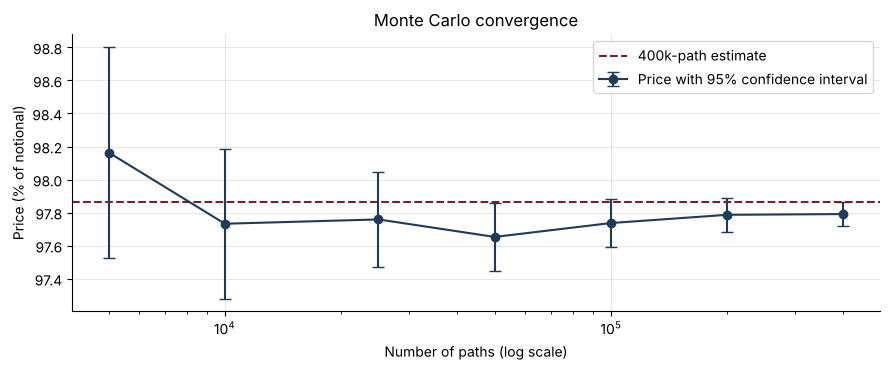

,Paths,price,stderr
0,5000,98.164,0.326
1,10000,97.733,0.231
2,25000,97.759,0.147
3,50000,97.653,0.104
4,100000,97.737,0.073
5,200000,97.787,0.052
6,400000,97.791,0.037


In [3]:
res = price(note, mkt, n_paths=400_000)
print(f"Price = {res['price']:.2f}% of notional   (standard error {res['stderr']:.3f}%)")

ns = [5_000, 10_000, 25_000, 50_000, 100_000, 200_000, 400_000]
conv = pd.DataFrame([{"Paths": n, **{k: price(note, mkt, n, seed=1)[k] for k in ["price", "stderr"]}} for n in ns])
plt.figure(figsize=(9, 3.8))
plt.errorbar(conv["Paths"], conv["price"], yerr=1.96 * conv["stderr"], color=NAVY, marker="o", capsize=4,
             label="Price with 95% confidence interval")
plt.axhline(res["price"], color=BORDEAUX, ls="--", label="400k-path estimate")
plt.xscale("log"); plt.xlabel("Number of paths (log scale)"); plt.ylabel("Price (% of notional)")
plt.title("Monte Carlo convergence"); plt.legend()
plt.tight_layout(); plt.savefig("images/convergence.png", dpi=150); plt.show()
conv.round(3)

## 3. The life of the note

What a client and a salesperson actually want to know: how likely is an early redemption,
how often are coupons paid, and what is the risk of losing capital?

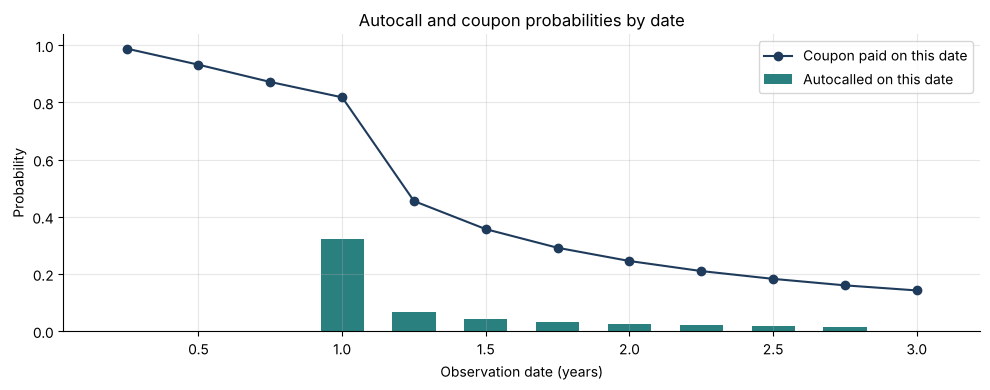

Expected life (years)              2.084
Called before maturity             0.540
Reaches maturity                   0.460
Capital loss at maturity           0.232
Average loss when a loss occurs    0.544
dtype: float64

In [4]:
life = pd.DataFrame({"Observation (years)": note.times, "Autocall probability": res["call_prob"],
                     "Coupon probability": res["coupon_prob"]})
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(life["Observation (years)"], life["Autocall probability"], width=0.15, color=TEAL, label="Autocalled on this date")
ax.plot(life["Observation (years)"], life["Coupon probability"], color=NAVY, marker="o", label="Coupon paid on this date")
ax.set(xlabel="Observation date (years)", ylabel="Probability", title="Autocall and coupon probabilities by date")
ax.legend(); plt.tight_layout(); plt.savefig("images/life.png", dpi=150); plt.show()

summary = pd.Series({"Expected life (years)": res["expected_life"],
                     "Called before maturity": 1 - res["prob_maturity"],
                     "Reaches maturity": res["prob_maturity"],
                     "Capital loss at maturity": res["prob_loss"],
                     "Average loss when a loss occurs": res["avg_loss_given_loss"]})
summary.round(3)

**Reading the results.** About a third of the notes are called at the first possible date:
when both stocks are above their initial level after one year, the issuer repays 100% plus
the coupons. The coupon probability then decays because the paths that are still alive are
the ones where at least one stock has fallen. The worst-of structure makes the protection
barrier much easier to breach than on a single stock, which is exactly what finances the
10% coupon.

## 4. Sensitivities (Greeks)

Computed by bump-and-reprice with **common random numbers** (the same draws before and
after the bump), so the differences are not drowned in Monte Carlo noise.

In [5]:
greeks = pd.Series(sensitivities(note, mkt, n_paths=200_000)).rename("Change in price (% of notional)")
greeks.round(3).to_frame()

,Change in price (% of notional)
Delta asset 1 (spot +1%),0.176
Delta asset 2 (spot +1%),0.232
"Vega (+1 vol pt, both assets)",-1.055
Correlation (+10 pts),0.516
Rho (+1% rate),-0.626


- **Short volatility:** the investor has sold a down-and-in put on the worst-of, so higher
  volatility lowers the note's value.
- **Long correlation:** the more the two stocks move together, the less likely one of them
  drags the basket down; worst-of products are a way for banks to buy correlation.
- **Positive delta** on both stocks, larger on the more volatile one, which is more often the worst.

## 5. Structuring: what coupon can we offer?

The structurer solves for the coupon that makes the note worth 98% (the remaining 2% is
the issuer's margin and distribution fees). With common random numbers the price is exactly
linear in the coupon, so two valuations are enough.

Fair coupon: 2.520% per quarter = 10.08% per year


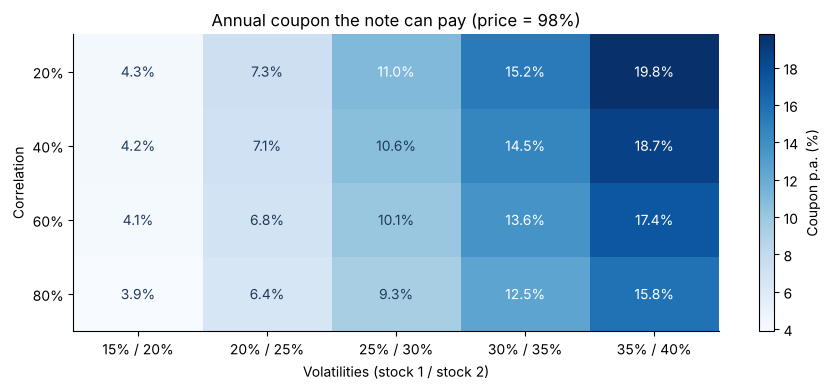

In [6]:
c = fair_coupon(note, mkt, target=98.0)
print(f"Fair coupon: {c:.3%} per quarter = {4 * c:.2%} per year")

vols = [0.15, 0.20, 0.25, 0.30, 0.35]
corrs = [0.2, 0.4, 0.6, 0.8]
grid = pd.DataFrame([[4 * fair_coupon(note, replace(mkt, vols=(v, v + 0.05), corr=rho), n_paths=60_000)
                      for v in vols] for rho in corrs],
                    index=[f"{rho:.0%}" for rho in corrs], columns=[f"{v:.0%} / {v + 0.05:.0%}" for v in vols])
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(grid.values * 100, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(vols)), grid.columns); ax.set_yticks(range(len(corrs)), grid.index)
for i in range(len(corrs)):
    for j in range(len(vols)):
        ax.text(j, i, f"{grid.values[i, j]:.1%}", ha="center", va="center",
                color="white" if grid.values[i, j] > grid.values.mean() else NAVY)
ax.set(xlabel="Volatilities (stock 1 / stock 2)", ylabel="Correlation",
       title="Annual coupon the note can pay (price = 98%)")
ax.grid(False); plt.colorbar(im, label="Coupon p.a. (%)")
plt.tight_layout(); plt.savefig("images/coupon_grid.png", dpi=150); plt.show()

**Takeaway for a sales or structuring desk.** High volatility and low correlation make
the coupon look attractive, but they are also what makes a capital loss more likely: the
headline coupon is the price of the risk the client is selling.

## Conclusions
- Exact simulation between observation dates, antithetic variates and common random
  numbers give stable prices (standard error around 0.04% of notional) and smooth Greeks.
- The tests in `test_autocall.py` check the limiting cases that have closed-form answers
  (zero-coupon and fixed-coupon bonds), the sign of every risk and the fair-coupon solver.
- **Next steps:** local or stochastic volatility (project 03), quanto adjustments,
  and pathwise or likelihood-ratio Greeks.